# Formative 2 – Product Recommendation Model (Training)

**Goal:** train a model that predicts **which product category a customer buys**, and save it in `models/`.

**Reads:** `data/cleaned_data/merged_dataset_encoded.csv` (made by `EDA/data_merging.ipynb`)
**Writes:** `models/product_model.joblib`

**Plan:** start with a very simple model, make it stronger step by step, and watch for **underfitting** (too simple) and **overfitting** (memorising).

**Three scores we will track**
- **Accuracy:** share of correct guesses. Guessing at random among 5 products gives about **20%**.
- **F1-score:** accuracy that also looks at every product fairly (macro average).
- **Loss (log loss):** how confident-and-wrong the model is. **Lower is better.** Pure guessing gives about **1.61**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

# Folder paths (this notebook lives in training_models/, so we go one level up)
CLEAN_DIR  = Path("../data/cleaned_data")
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

### 1. Set up: features, target, and a fair split

- **Features:** everything except the IDs. **Target:** `product_category`.
- Some customers have several purchases. We split **by customer**, so a customer is never in both training and test data. Otherwise the model could just remember people.
- **80% train / 20% test.** The test set is kept locked until the very end.

In [2]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix, ConfusionMatrixDisplay
import warnings; warnings.filterwarnings("ignore")

data = pd.read_csv(CLEAN_DIR / "merged_dataset_encoded.csv")
y = data["product_category"]
X = data.drop(columns=["product_category", "customer_id", "transaction_id"])
groups = data["customer_id"]

train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

print("Features:", X.shape[1])
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Customers shared between train and test:", len(set(g_train) & set(groups.iloc[test_idx])))

Features: 23
Train rows: 125 | Test rows: 25
Customers shared between train and test: 0


### 2. Baseline: always guess the most common product
Any real model must beat this. We score every model with **5-fold cross-validation** on the training data (the model is tested on customers it has not seen).

In [3]:
cv = GroupKFold(n_splits=5)

def check(model, name):
    r = cross_validate(model, X_train, y_train, groups=g_train, cv=cv, return_train_score=True,
                       scoring=["accuracy", "f1_macro", "neg_log_loss"])
    row = {"Model": name,
           "Train acc": r["train_accuracy"].mean(), "Val acc": r["test_accuracy"].mean(),
           "Val F1": r["test_f1_macro"].mean(),
           "Train loss": -r["train_neg_log_loss"].mean(), "Val loss": -r["test_neg_log_loss"].mean()}
    return row

results = [check(DummyClassifier(strategy="prior"), "Baseline (most common)")]
pd.DataFrame(results).round(2)

,Model,Train acc,Val acc,Val F1,Train loss,Val loss
0,Baseline (most common),0.25,0.18,0.06,1.59,1.65


The baseline gets about 20% accuracy and a loss near 1.6. This is our **starting line**.

### 3. Start tiny (underfit) and grow the model
We use a **Random Forest** (many small decision trees voting together). We begin with **1 tree, 1 question deep**, then add more trees and more depth.

In [4]:
steps = [
    ("1 tree, depth 1   (tiny)",       dict(n_estimators=1,   max_depth=1)),
    ("10 trees, depth 2",              dict(n_estimators=10,  max_depth=2)),
    ("50 trees, depth 3",              dict(n_estimators=50,  max_depth=3)),
    ("100 trees, depth 5",             dict(n_estimators=100, max_depth=5)),
    ("300 trees, no depth limit",      dict(n_estimators=300, max_depth=None)),
]
for name, params in steps:
    results.append(check(RandomForestClassifier(random_state=42, **params), name))

progress = pd.DataFrame(results).round(2)
progress["Gap (train - val acc)"] = (progress["Train acc"] - progress["Val acc"]).round(2)
progress

,Model,Train acc,Val acc,Val F1,Train loss,Val loss,Gap (train - val acc)
0,Baseline (most common),0.25,0.18,0.06,1.59,1.65,0.07
1,"1 tree, depth 1 (tiny)",0.29,0.17,0.08,1.90,3.13,0.12
2,"10 trees, depth 2",0.50,0.15,0.12,1.36,1.71,0.35
3,"50 trees, depth 3",0.71,0.20,0.17,1.17,1.68,0.51
4,"100 trees, depth 5",0.96,0.22,0.18,0.81,1.69,0.74
5,"300 trees, no depth limit",1.00,0.21,0.17,0.34,1.77,0.79


**How to read this table**
- **Tiny model:** low train *and* validation scores. It is too simple, so it is **underfitting**.
- **As the model grows:** train accuracy climbs to almost **100%**, but validation accuracy barely moves. The growing **gap** means the model is **memorising** the training rows (**overfitting**), not learning.
- Validation loss never beats the baseline (1.65). The biggest models are slightly worse (1.77).

### 4. Watch the loss over training rounds

Here we train a **boosting** model, which learns **one small step (round) at a time**, like epochs. We plot the loss after every round for training data and for unseen data.

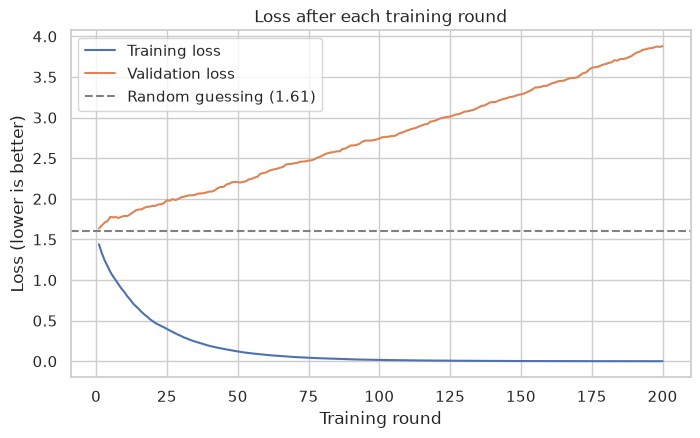

Best validation loss: 1.64 at round 1


In [5]:
# one extra split inside the training data, so the curve uses unseen customers
inner_tr, inner_va = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=1).split(X_train, y_train, g_train))
Xa, Xb = X_train.iloc[inner_tr], X_train.iloc[inner_va]
ya, yb = y_train.iloc[inner_tr], y_train.iloc[inner_va]

gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42).fit(Xa, ya)

train_loss = [log_loss(ya, p, labels=gb.classes_) for p in gb.staged_predict_proba(Xa)]
val_loss   = [log_loss(yb, p, labels=gb.classes_) for p in gb.staged_predict_proba(Xb)]

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 201), train_loss, label="Training loss")
plt.plot(range(1, 201), val_loss, label="Validation loss")
plt.axhline(np.log(5), color="grey", linestyle="--", label="Random guessing (1.61)")
plt.title("Loss after each training round")
plt.xlabel("Training round"); plt.ylabel("Loss (lower is better)")
plt.legend(); plt.show()

print(f"Best validation loss: {min(val_loss):.2f} at round {int(np.argmin(val_loss)) + 1}")

**What it shows:** training loss keeps falling (the model keeps memorising), but validation loss is lowest at **round 1** and then **only goes up**.
Training longer makes it **worse** on new customers. So we need a **small, controlled** model.

### 5. Control the model (find the balance)

We keep trees shallow (`max_depth=3`) and demand **more rows per leaf** (`min_samples_leaf`), so the model cannot make tiny rules for single customers. We try 5, 10 and 20 rows.

In [6]:
for leaf in [5, 10, 20]:
    params = dict(n_estimators=200, max_depth=3, min_samples_leaf=leaf, random_state=42)
    results.append(check(RandomForestClassifier(**params), f"200 trees, depth 3, min {leaf} rows per leaf"))

balanced_params = dict(n_estimators=200, max_depth=3, min_samples_leaf=20, random_state=42)  # chosen below

progress = pd.DataFrame(results).round(2)
progress["Gap (train - val acc)"] = (progress["Train acc"] - progress["Val acc"]).round(2)
progress

,Model,Train acc,Val acc,Val F1,Train loss,Val loss,Gap (train - val acc)
0,Baseline (most common),0.25,0.18,0.06,1.59,1.65,0.07
1,"1 tree, depth 1 (tiny)",0.29,0.17,0.08,1.90,3.13,0.12
2,"10 trees, depth 2",0.50,0.15,0.12,1.36,1.71,0.35
3,"50 trees, depth 3",0.71,0.20,0.17,1.17,1.68,0.51
4,"100 trees, depth 5",0.96,0.22,0.18,0.81,1.69,0.74
5,"300 trees, no depth limit",1.00,0.21,0.17,0.34,1.77,0.79
6,"200 trees, depth 3, min 5 rows per leaf",0.65,0.21,0.13,1.26,1.67,0.44
7,"200 trees, depth 3, min 10 rows per leaf",0.54,0.18,0.13,1.35,1.66,0.36
8,"200 trees, depth 3, min 20 rows per leaf",0.40,0.17,0.11,1.49,1.66,0.23


**Result:** the more we limit the model, the **smaller the gap** gets (0.44 → 0.23). Validation loss stays about the same (1.66) in every case.
We choose **min 20 rows per leaf**: same loss, smallest gap, so it memorises the least.
The honest catch: no setting clearly beats the baseline. Next we find out why.

### 6. Is there anything to learn? (reality check)

We train the **same model on shuffled answers** (products randomly mixed up). If it scores the same as with the real answers, then the features have **no real link** to the product.

In [7]:
rng = np.random.RandomState(0)
y_shuffled = pd.Series(rng.permutation(y_train.values), index=y_train.index)

real = cross_validate(RandomForestClassifier(**balanced_params), X_train, y_train, groups=g_train, cv=cv, scoring=["accuracy", "f1_macro"])
fake = cross_validate(RandomForestClassifier(**balanced_params), X_train, y_shuffled, groups=g_train, cv=cv, scoring=["accuracy", "f1_macro"])

print(f"Real answers     -> accuracy {real['test_accuracy'].mean():.2f} | F1 {real['test_f1_macro'].mean():.2f}")
print(f"Shuffled answers -> accuracy {fake['test_accuracy'].mean():.2f} | F1 {fake['test_f1_macro'].mean():.2f}")

Real answers     -> accuracy 0.17 | F1 0.11
Shuffled answers -> accuracy 0.13 | F1 0.05


**What it means:** real answers score only a few points higher than random ones, which is too small to trust with this little data.
So the features carry **very little signal** about which product is bought (the EDA also showed the features look alike for every product).
Tuning cannot fix this: a model cannot find a pattern that is not in the data. We will explain this honestly in the report.

### 7. Final model: test on the locked test set

We train the controlled model on all training data and test it **once** on the 20% we kept aside.

In [8]:
final_model = RandomForestClassifier(**balanced_params).fit(X_train, y_train)

pred = final_model.predict(X_test)
proba = final_model.predict_proba(X_test)

test_acc  = accuracy_score(y_test, pred)
test_f1   = f1_score(y_test, pred, average="macro")
test_loss = log_loss(y_test, proba, labels=final_model.classes_)

baseline = DummyClassifier(strategy="prior").fit(X_train, y_train)
base_loss = log_loss(y_test, baseline.predict_proba(X_test), labels=baseline.classes_)

print(f"Accuracy : {test_acc:.2f}   (random guessing = 0.20)")
print(f"F1-score : {test_f1:.2f}")
print(f"Loss     : {test_loss:.2f}   (baseline = {base_loss:.2f}, random guessing = 1.61)")
print(f"Test rows: {len(y_test)}")

Accuracy : 0.20   (random guessing = 0.20)
F1-score : 0.11
Loss     : 1.69   (baseline = 1.66, random guessing = 1.61)
Test rows: 25


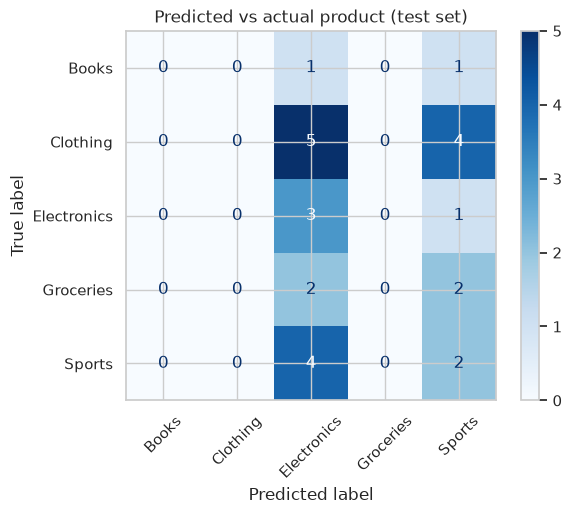

In [9]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45, cmap="Blues")
plt.title("Predicted vs actual product (test set)")
plt.show()

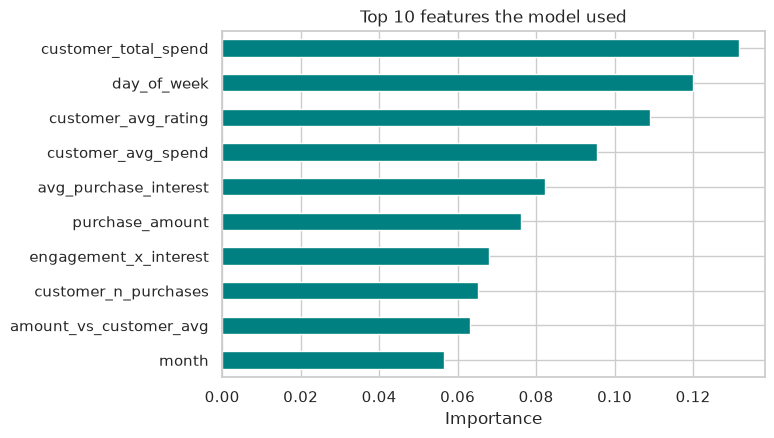

In [10]:
importance = pd.Series(final_model.feature_importances_, index=X.columns).sort_values().tail(10)
importance.plot(kind="barh", figsize=(7, 4.5), color="teal")
plt.title("Top 10 features the model used")
plt.xlabel("Importance")
plt.show()

**Reading the results**
- Accuracy is at or below random guessing, and loss is not better than the baseline. This matches the reality check. 
- The test set has only **25 rows** (a few right or wrong answers moves the score a lot), so treat these numbers as rough.
- Feature importances are small and spread out (see the chart), which also says no feature is strongly predictive.

### 8. Save the model

We save the model with its feature list and product names, so the command-line app (Task 6) can load it later.

In [11]:
joblib.dump({"model": final_model,
             "features": list(X.columns),
             "classes": list(final_model.classes_)},
            MODELS_DIR / "product_model.joblib")
print("Saved:", MODELS_DIR / "product_model.joblib")

Saved: ../models/product_model.joblib


## Summary

- **Started tiny** (underfit) → **grew the model** (overfit) → **controlled it** (smallest train-vs-validation gap).
- **Found** that real answers score only slightly above shuffled ones, so the dataset has **very little signal**. Accuracy stays near random guessing (about 20%), whatever we tune.
- **Saved** the model, its feature list and product names to `models/product_model.joblib`, ready for the command-line app (Task 6).